<a href="https://colab.research.google.com/github/HmanseyWBS/HmanseyWBS---AnalyticsEngineering/blob/main/Copy_of_2_03_practice_bike_hire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [1]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/dbsession/bike-hire-practice.zip"

DATA_DIR = "/content/bikes"
# Download only if no CSV files are there yet. The CSVs may sit inside a folder
# within the zip; the search below looks in sub-folders too.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "/content/bikes.zip")
    zipfile.ZipFile("/content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))


trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [2]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


In [3]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id              object
bike_id              object
start_station_id     object
end_station_id       object
start_time           object
duration_min        float64
user_type            object
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## 1. Look at the data

*What does one row of each table represent? Which columns will you use? What looks odd, missing or inconsistent? Write down what you find.*

In [5]:
# Check for missing values in the trips table
trips = tables["trips"]
print("Missing value count per column in trips:")
display(trips.isnull().sum())

print("\nSummary info for trips:")
display(trips.info())

Missing value count per column in trips:


,0
trip_id,0
bike_id,0
start_station_id,0
end_station_id,0
start_time,0
duration_min,30
user_type,0



Summary info for trips:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   trip_id           612 non-null    object 
 1   bike_id           612 non-null    object 
 2   start_station_id  612 non-null    object 
 3   end_station_id    612 non-null    object 
 4   start_time        612 non-null    object 
 5   duration_min      582 non-null    float64
 6   user_type         612 non-null    object 
dtypes: float64(1), object(6)
memory usage: 33.6+ KB


None

In [6]:
# Check for missing values and duplicates in stations and bikes tables
bikes = tables["bikes"]
stations = tables["stations"]

print("=== BIKES TABLE ===")
print("Missing values:")
display(bikes.isnull().sum())
print(f"Duplicate bike_id count: {bikes.duplicated(subset=['bike_id']).sum()}")
print(f"Unique bike types: {bikes['bike_type'].unique()}")

print("\n=== STATIONS TABLE ===")
print("Missing values:")
display(stations.isnull().sum())
print(f"Duplicate station_id count: {stations.duplicated(subset=['station_id']).sum()}")
print(f"Unique zones: {stations['zone'].unique()}")

=== BIKES TABLE ===
Missing values:


,0
bike_id,0
bike_type,0
purchase_year,0


Duplicate bike_id count: 0
Unique bike types: ['Standard' 'Electric ' 'electric' 'STANDARD' 'standard' 'Electric'
 'E-bike']

=== STATIONS TABLE ===
Missing values:


,0
station_id,0
station_name,0
zone,0
capacity,1


Duplicate station_id count: 0
Unique zones: ['Centre' 'North' 'West' 'South' 'East']


In [10]:
# Inspect the stations table where there are missing values (like capacity)
stations = tables["stations"]
print("Stations with missing values:")
display(stations[stations.isnull().any(axis=1)])

Stations with missing values:


,station_id,station_name,zone,capacity
8,S09,Old Town Hall,Centre,NaN


## 2. Clean and prepare

*Decide what to do about each problem you found, say why, and do it. Short cells that you can re-run are better than one long cell.*

In [15]:
# 1. Clean the bike_type column in bikes table
bikes_clean = tables["bikes"].copy()
bikes_clean["bike_type"] = bikes_clean["bike_type"].str.strip().str.title()
bikes_clean["bike_type"] = bikes_clean["bike_type"].replace({"E-Bike": "Electric"})

print("Cleaned unique bike types:")
print(bikes_clean["bike_type"].value_counts())

# 2. Handle missing duration_min in trips table
trips_clean = tables["trips"].copy()
trips_clean = trips_clean.dropna(subset=["duration_min"])
print(f"\nTrips remaining after removing missing durations: {len(trips_clean)} (dropped 30 rows)")

# Register cleaned tables back to DuckDB
tables["bikes_clean"] = bikes_clean
tables["trips_clean"] = trips_clean
con.register("bikes_clean", bikes_clean)
con.register("trips_clean", trips_clean)

Cleaned unique bike types:
bike_type
Standard    47
Electric    13
Name: count, dtype: int64

Trips remaining after removing missing durations: 582 (dropped 30 rows)


In [16]:
# 1. Clean the bike_type column in bikes table
bikes_clean = tables["bikes"].copy()
# Strip whitespace and make title case, then group E-bike under Electric
bikes_clean["bike_type"] = bikes_clean["bike_type"].str.strip().str.title()
bikes_clean["bike_type"] = bikes_clean["bike_type"].replace({"E-Bike": "Electric"})

print("Cleaned unique bike types:")
print(bikes_clean["bike_type"].value_counts())

# 2. Handle missing duration_min in trips table
trips_clean = tables["trips"].copy()
# We drop the 30 rows with missing durations because we can't accurately compute averages with missing durations
trips_clean = trips_clean.dropna(subset=["duration_min"])
print(f"\nTrips remaining after removing missing durations: {len(trips_clean)} (dropped 30 rows)")

# Register cleaned tables back to DuckDB and save in variables
tables["bikes_clean"] = bikes_clean
tables["trips_clean"] = trips_clean
con.register("bikes_clean", bikes_clean)
con.register("trips_clean", trips_clean)

Cleaned unique bike types:
bike_type
Standard    47
Electric    13
Name: count, dtype: int64

Trips remaining after removing missing durations: 582 (dropped 30 rows)


In [14]:
# Summary of missing values across all tables
for name, df in tables.items():
    print(f"\n=== Missing values in '{name}' table ===")
    missing_counts = df.isnull().sum()
    display(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "No missing values")


=== Missing values in 'trips' table ===


,0
duration_min,30



=== Missing values in 'bikes' table ===


'No missing values'


=== Missing values in 'stations' table ===


,0
capacity,1



=== Missing values in 'bikes_clean' table ===


'No missing values'


=== Missing values in 'trips_clean' table ===


'No missing values'

## 3. Join and aggregate

*Join the tables and calculate the answer. Note how many rows you expect after each join, then check.*

In [18]:
# Join the tables and calculate the average duration by bike type and zone
query = """
SELECT
    b.bike_type,
    s.zone,
    COUNT(t.trip_id) AS total_trips,
    ROUND(AVG(t.duration_min), 2) AS avg_duration_min
FROM trips_clean AS t
JOIN bikes_clean AS b ON t.bike_id = b.bike_id
JOIN stations AS s ON t.start_station_id = s.station_id
GROUP BY b.bike_type, s.zone
ORDER BY b.bike_type, s.zone
"""

results = q(query)
display(results)

,bike_type,zone,total_trips,avg_duration_min
0,Electric,Centre,82,14.44
1,Electric,East,13,15.38
2,Electric,North,24,15.96
3,Electric,South,24,13.42
4,Electric,West,22,15.68
5,Standard,Centre,221,38.32
6,Standard,East,20,19.50
7,Standard,North,39,20.36
8,Standard,South,61,43.30
9,Standard,West,76,19.82


## 4. Check

*How do you know the answer is right? Compare a count, spot check a few records, or recalculate one number a different way. What did you find?*

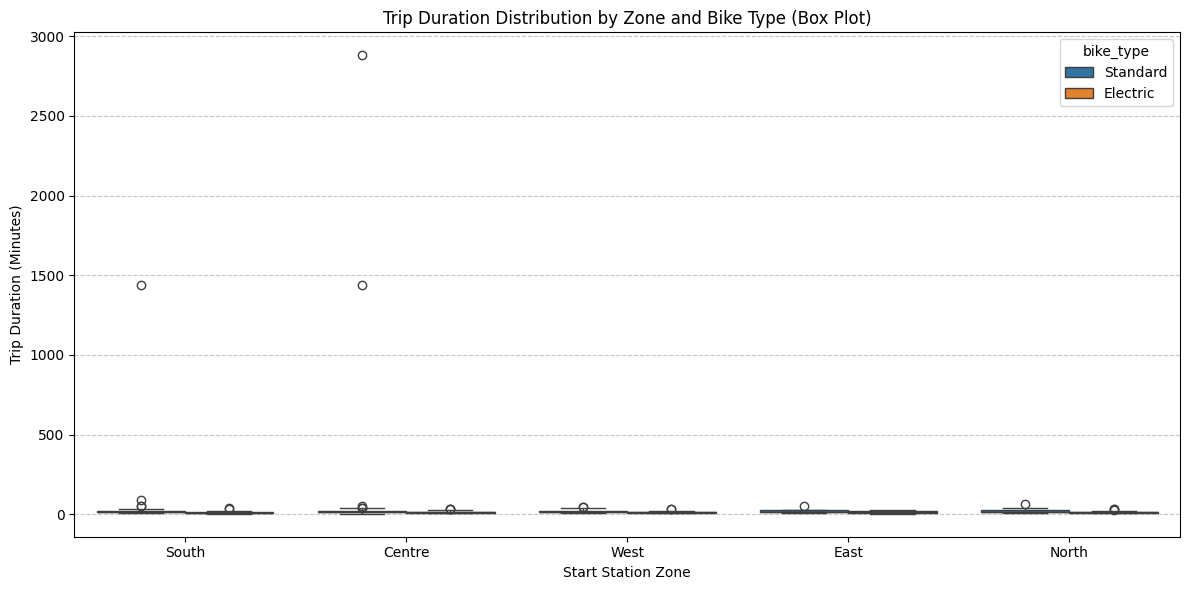

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Join trips and bikes to get bike types and zones for individual trips
trips_with_details = q("""
    SELECT t.duration_min, b.bike_type, s.zone
    FROM trips_clean AS t
    JOIN bikes_clean AS b ON t.bike_id = b.bike_id
    JOIN stations AS s ON t.start_station_id = s.station_id
""")

# Create the box and whisker plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=trips_with_details, x='zone', y='duration_min', hue='bike_type')
plt.title('Trip Duration Distribution by Zone and Bike Type (Box Plot)')
plt.xlabel('Start Station Zone')
plt.ylabel('Trip Duration (Minutes)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

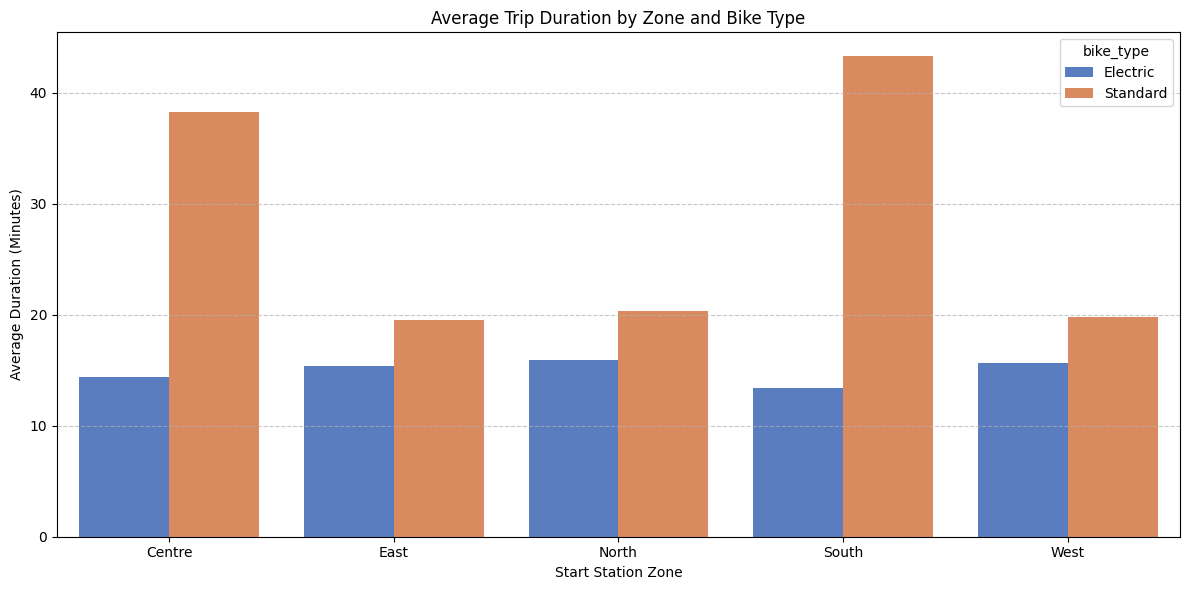

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar chart showing average trip duration by zone and bike type
plt.figure(figsize=(12, 6))
sns.barplot(data=results, x='zone', y='avg_duration_min', hue='bike_type', palette='muted')
plt.title('Average Trip Duration by Zone and Bike Type')
plt.xlabel('Start Station Zone')
plt.ylabel('Average Duration (Minutes)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

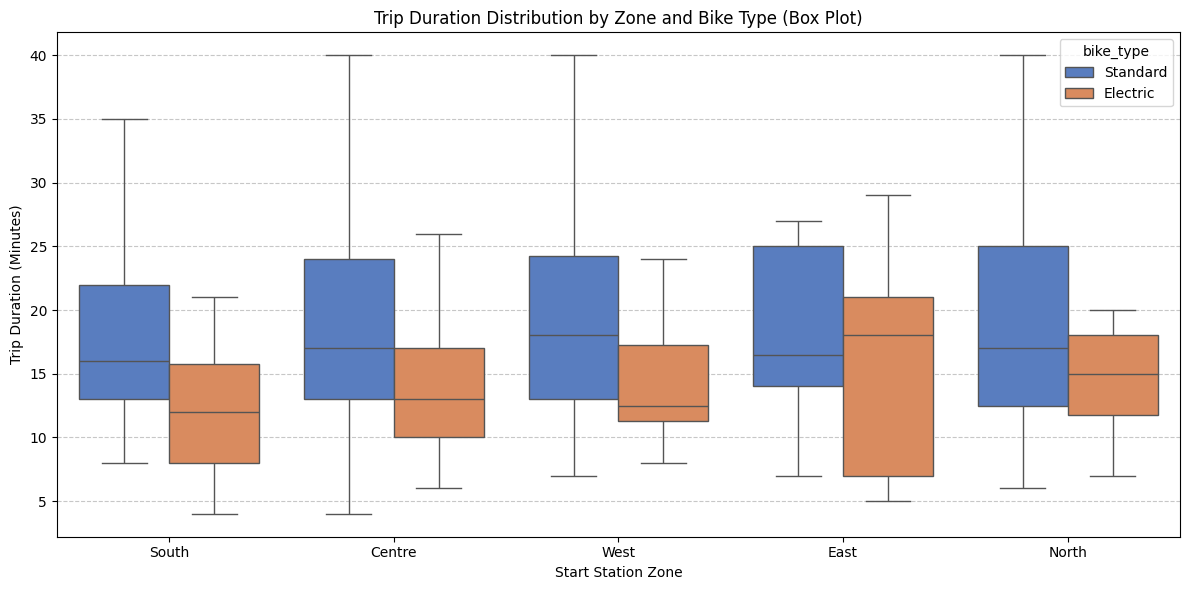

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a box-and-whisker plot to show duration distributions (removing outlier fliers)
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=trips_with_details,
    x='zone',
    y='duration_min',
    hue='bike_type',
    palette='muted',
    showfliers=False
)
plt.title('Trip Duration Distribution by Zone and Bike Type (Box Plot)')
plt.xlabel('Start Station Zone')
plt.ylabel('Trip Duration (Minutes)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 5. Prompts and AI notes

*Paste each prompt as you sent it. Note what you accepted, changed or rejected and why.*

## 6. What I could not verify

*What remains unchecked? What would you do next?*